<a href="https://colab.research.google.com/github/nasy-sr/artificial-intelligence-coursework-2024-genap/blob/main/03-multi-class-text-classification-20-newsgroups.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Setup dan Akses File dari Google Drive**

In [ ]:
# Cell 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set(style='darkgrid', font_scale=1.6)
import spacy
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.naive_bayes import MultinomialNB

In [ ]:
#Mont Google Drive
from google.colab import drive
drive.mount('/content/drive')

#Path ke file csv
file_path = '/content/drive/MyDrive/Colab Notebooks/AI_Class/20_newsgroup.csv'

#Load dataset
df = pd.read_csv(file_path, encoding='latin-1')
df.head()

Mounted at /content/drive


,Unnamed: 0,text,target,title,date
0,0,I was wondering if anyone out there could enli...,7,rec.autos,2025-05-07 02:05:02.154073
1,17,I recently posted an article asking what kind ...,7,rec.autos,2025-05-07 02:05:02.154073
2,29,\nIt depends on your priorities. A lot of peo...,7,rec.autos,2025-05-07 02:05:02.154073
3,56,an excellent automatic can be found in the sub...,7,rec.autos,2025-05-07 02:05:02.154073
4,64,: Ford and his automobile. I need information...,7,rec.autos,2025-05-07 02:05:02.154073


**2. Pembersihan Dataset**

In [ ]:
#Cell 2: Load Dataset

#Read CSV File
df=pd.read_csv(file_path, encoding='latin-1')

#Drop rows with missing text
df.dropna(subset=['text']).reset_index(drop=True)

#Show shape and preview
print("Dataset size:", df.shape)
df.head()

Dataset size: (11314, 5)


,Unnamed: 0,text,target,title,date
0,0,I was wondering if anyone out there could enli...,7,rec.autos,2025-05-07 02:05:02.154073
1,17,I recently posted an article asking what kind ...,7,rec.autos,2025-05-07 02:05:02.154073
2,29,\nIt depends on your priorities. A lot of peo...,7,rec.autos,2025-05-07 02:05:02.154073
3,56,an excellent automatic can be found in the sub...,7,rec.autos,2025-05-07 02:05:02.154073
4,64,: Ford and his automobile. I need information...,7,rec.autos,2025-05-07 02:05:02.154073


**3. Preprocessing Data**

In [ ]:
# Cell 3: Explore Label/Kelas

print("Unique labels:", df['title'].unique())
print("\nLabel Encoding (target):", df['target'].unique())
print("nExample Article:\n", df['text'][0])

Unique labels: ['rec.autos' 'comp.sys.mac.hardware' 'comp.graphics' 'sci.space'
 'talk.politics.guns' 'sci.med' 'comp.sys.ibm.pc.hardware'
 'comp.os.ms-windows.misc' 'rec.motorcycles' 'talk.religion.misc'
 'misc.forsale' 'alt.atheism' 'sci.electronics' 'comp.windows.x'
 'rec.sport.hockey' 'rec.sport.baseball' 'soc.religion.christian'
 'talk.politics.mideast' 'talk.politics.misc' 'sci.crypt']

Label Encoding (target): [ 7  4  1 14 16 13  3  2  8 19  6  0 12  5 10  9 15 17 18 11]
nExample Article:
 I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


**4. Split Data: Training dan Testing**

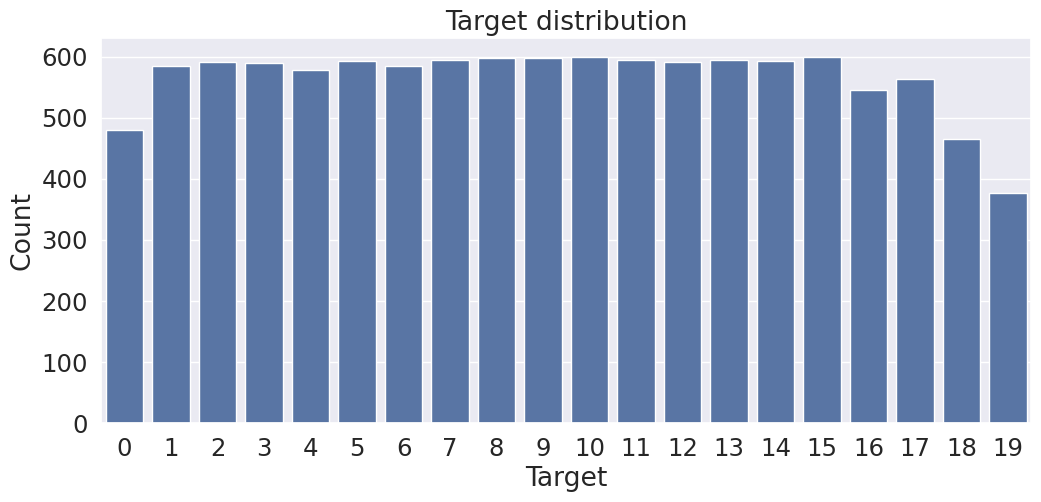

In [ ]:
# Cell 4: Visualisasi distribusi target (Label/Kelas)

plt.figure(figsize=(12, 5))
sns.countplot(x=df['target'])
plt.title('Target distribution')
plt.xlabel('Target')
plt.ylabel('Count')
plt.show()

**5. Feature Extraction: TF-IDF atau CountVectorizer**

In [ ]:
# Cell 5: custom tokenizer menggunakan library spacy

nlp = spacy.blank('en')

def custom_tokenizer(doc):
    return [t.text for t in nlp(doc) if not t.is_punct and not t.is_space and t.is_alpha]

**6. Training Model Naive Bayes**

In [ ]:
# Cell 6: Train-Test Split (40% sebagai testing)

X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['target'], test_size=0.4, random_state=42, stratify=df['target']
    )

**7. Evaluasi Model**

In [ ]:
# Cek apakah ada NaN sebelum vectorisasi
print("Jumlah NaN di X_train:", X_train.isna().sum())
print("Jumlah NaN di X_test:", X_test.isna().sum())

# 🔧 Jika ada NaN, ganti dengan string kosong
X_train = X_train.fillna('')
X_test = X_test.fillna('')

Jumlah NaN di X_train: 141
Jumlah NaN di X_test: 77


In [ ]:
# Vectorisasi teks dengan CountVectorizer dan custom tokenizer

vectorizer = CountVectorizer(tokenizer=custom_tokenizer)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)


ValueError: np.nan is an invalid document, expected byte or unicode string.

---

## 🔍 **1. Confusion Matrix**

Confusion Matrix menampilkan jumlah prediksi model yang benar dan salah untuk setiap kelas. Dalam kasus :

```
               Predicted
               Ham   Spam
Actual Ham    [1930     0]
Actual Spam   [  74   225]
```

Artinya:

* **True Negative (TN) = 1930**: SMS Ham yang diprediksi benar sebagai Ham.
* **False Negative (FN) = 74**: SMS Spam yang salah diprediksi sebagai Ham.
* **True Positive (TP) = 225**: SMS Spam yang diprediksi benar sebagai Spam.
* **False Positive (FP) = 0**: SMS Ham yang salah diprediksi sebagai Spam.

---

## 📏 **2. Accuracy**

**Definisi:**

> Persentase total prediksi yang benar dari semua prediksi.

**Rumus:**

$$
\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}
$$

**Hasil :**

$$
\text{Accuracy} = \frac{225 + 1930}{225 + 1930 + 0 + 74} = 0.9668 \ (\text{atau } 96.68\%)
$$

**Interpretasi:**
96.68% dari semua SMS diprediksi dengan benar. Tapi hati-hati: *Accuracy bisa menipu* jika kelas tidak seimbang (misalnya jika 90% pesan adalah Ham).

---

## 🎯 **3. Precision**

**Definisi:**

> Dari semua prediksi Spam yang dibuat model, berapa persen yang benar-benar Spam?

**Rumus:**

$$
\text{Precision} = \frac{TP}{TP + FP}
$$

**Untuk Spam:**

$$
\frac{225}{225 + 0} = 1.00
$$

**Interpretasi:**
Model tidak pernah salah mengira Ham sebagai Spam (**tidak ada false positives**), artinya semua pesan yang diklasifikasikan sebagai spam memang benar spam.

---

## 🎯 **4. Recall (Sensitivity / True Positive Rate)**

**Definisi:**

> Dari semua Spam sebenarnya, berapa banyak yang berhasil dikenali sebagai Spam?

**Rumus:**

$$
\text{Recall} = \frac{TP}{TP + FN}
$$

**Untuk Spam:**

$$
\frac{225}{225 + 74} \approx 0.75
$$

**Interpretasi:**
Hanya 75% dari semua spam berhasil terdeteksi. 25% lolos sebagai Ham (false negatives), yang bisa jadi masalah dalam deteksi spam.

---

## ⚖️ **5. F1-Score**

**Definisi:**

> Harmonic mean dari Precision dan Recall. Cocok untuk data tidak seimbang.

**Rumus:**

$$
\text{F1} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}
$$

**Untuk Spam:**

$$
F1 = 2 \times \frac{1.00 \times 0.75}{1.00 + 0.75} \approx 0.86
$$

**Interpretasi:**
F1-Score memberi gambaran menyeluruh tentang kinerja deteksi spam. Nilai 0.86 cukup baik, tapi masih bisa ditingkatkan.

---

## 🧮 **6. Support**

**Definisi:**

> Jumlah instance (data) sebenarnya dalam setiap kelas.

**Spam:** 299
**Ham:** 1930

**Interpretasi:**
Kelas Ham jauh lebih banyak, yang bisa menyebabkan model cenderung memprioritaskan akurasi pada Ham jika tidak diseimbangkan.

---

## 🧠 **7. Macro Average (macro avg)**

**Definisi:**

> Rata-rata metrik (precision, recall, f1) untuk semua kelas, tanpa memperhatikan jumlah data di tiap kelas.

**Rumus:**

$$
\text{Macro Precision} = \frac{P_{Ham} + P_{Spam}}{2}
$$

**Interpretasi:**
Mengukur performa model secara seimbang antar kelas. Penting untuk tahu apakah model bekerja adil antara Spam dan Ham.

---

## 🧠 **8. Weighted Average (weighted avg)**

**Definisi:**

> Rata-rata metrik dengan memperhitungkan jumlah instance di setiap kelas (support).

**Interpretasi:**
Menggambarkan performa keseluruhan sambil mempertimbangkan distribusi kelas. Di dataset ini, hasil weighted avg lebih mendekati performa kelas Ham karena datanya jauh lebih banyak.

---

## 📌 **Kesimpulan**

| Metrik           | Artinya dalam Konteks Spam Filtering                              | Hasil  |
| ---------------- | ----------------------------------------------------------------- | ---------- |
| Accuracy         | Berapa banyak SMS diklasifikasikan dengan benar                   | 96.68%     |
| Precision (Spam) | Dari semua yang diprediksi sebagai Spam, berapa yang benar        | 100%       |
| Recall (Spam)    | Dari semua Spam yang ada, berapa yang terdeteksi                  | 75%        |
| F1-Score (Spam)  | Keseimbangan antara precision dan recall                          | 86%        |
| Macro Avg        | Rata-rata performa setiap kelas (tidak memperhatikan jumlah data) | 98%        |
| Weighted Avg     | Rata-rata performa, mempertimbangkan jumlah data tiap kelas       | 97%        |


In [ ]:
# Cell 8: Train Naive bayes Classifier

clf = MultinomialNB()
clf.fit(X_train_vec, y_train)

MultinomialNB()

**9. Visualisasi Confusion Matrix**

In [ ]:
# cell 9: Prediksi and Evaluasi

y_pred = clf.predict(X_test_vec)
print("F1 Score (macro):", f1_score(y_test, y_pred, average='macro'))

F1 Score (macro): 0.5632886688773172


NameError: name 'ConfusionMathrixDisplay' is not defined

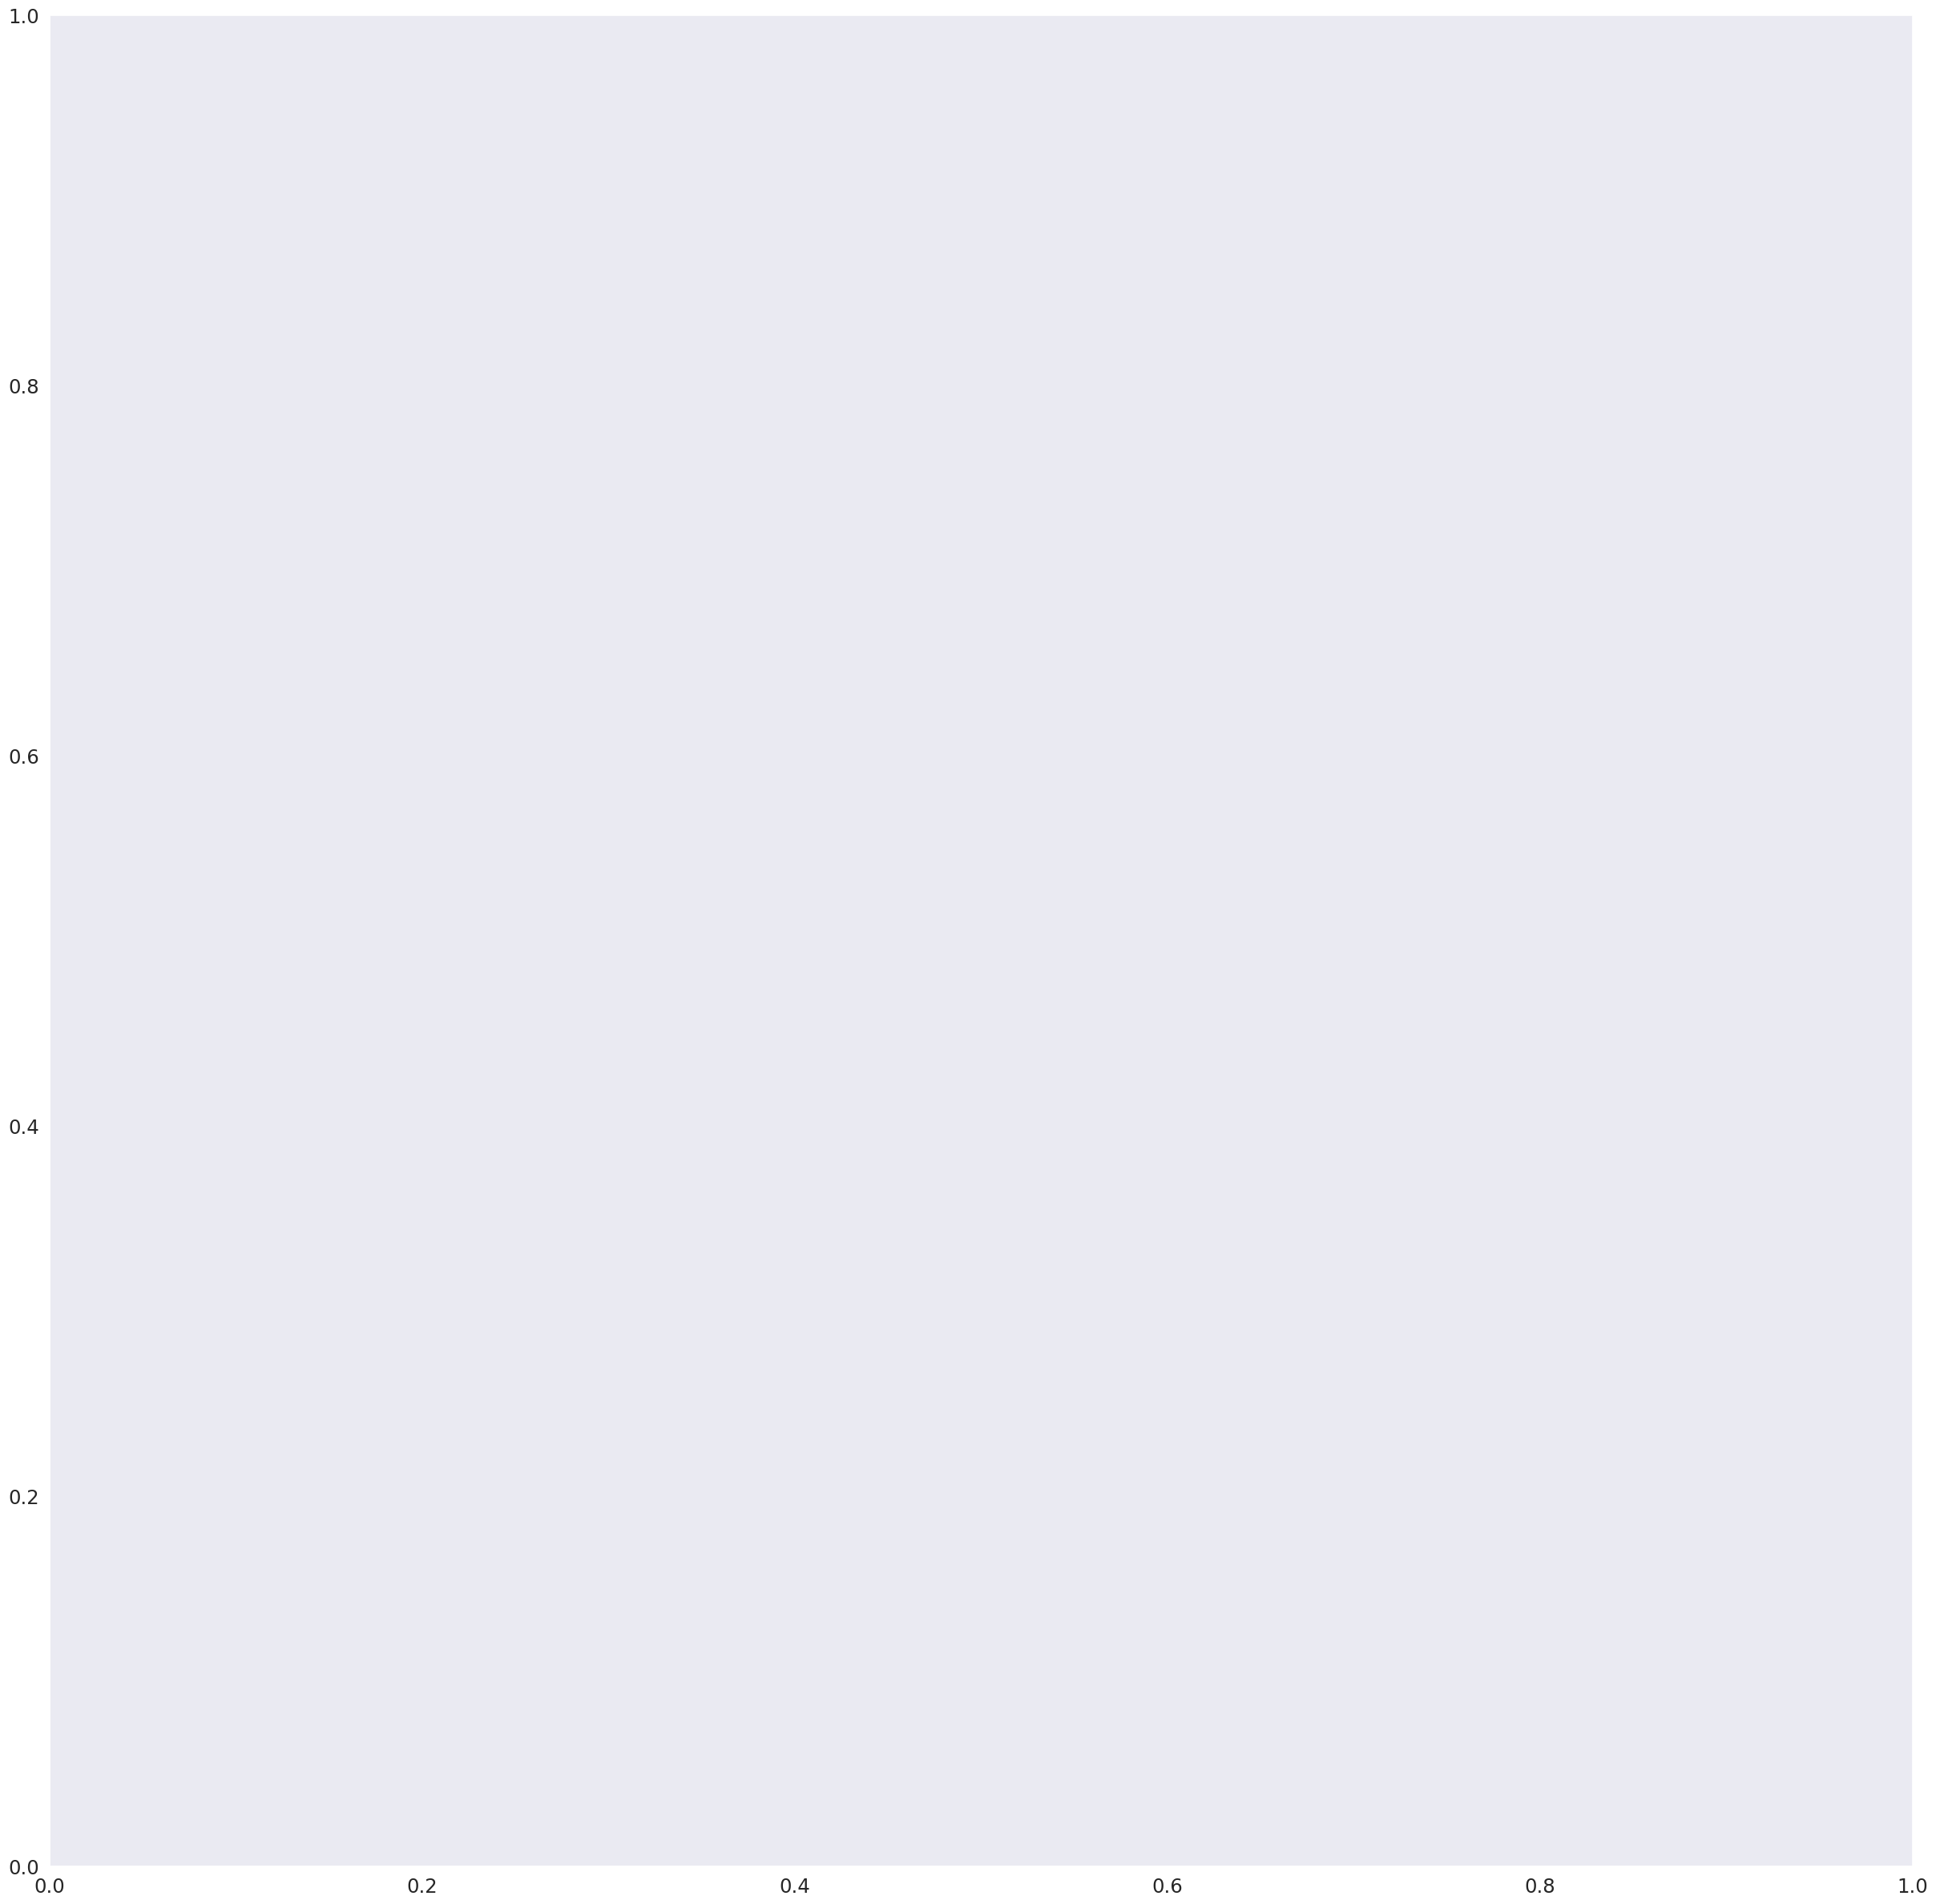

In [ ]:
# Cell 10: Confusion matrix

fig, ax = plt.subplots(figsize=(30,30))
ax.grid(False)

ConfusionMathrixDisplay.from_estimator(
     clf, X_test_vec, y_test, normalize='true',
    display_labels=df['title'].unique(), ax=ax
)
plt.title("Normalized Confusion Matrix")
plt.show()

In [ ]:
#Cell 11: Classification report

print(classification_report(y_test, y_pred, target_names=df['title'].unique()))

                          precision    recall  f1-score   support

               rec.autos       0.73      0.30      0.43       192
   comp.sys.mac.hardware       0.63      0.26      0.37       234
           comp.graphics       0.72      0.21      0.33       236
               sci.space       0.54      0.68      0.60       236
      talk.politics.guns       0.63      0.58      0.60       231
                 sci.med       0.47      0.88      0.61       237
comp.sys.ibm.pc.hardware       0.85      0.46      0.60       234
 comp.os.ms-windows.misc       0.90      0.51      0.65       238
         rec.motorcycles       0.91      0.62      0.73       239
      talk.religion.misc       0.94      0.70      0.80       239
            misc.forsale       0.57      0.77      0.65       240
             alt.atheism       0.44      0.82      0.57       238
         sci.electronics       0.89      0.35      0.50       236
          comp.windows.x       0.80      0.76      0.78       238
        r